In [1]:
# Mengimpor modul pandas untuk memproses dan mengelola data dalam bentuk tabel/dataframe
import pandas as pd

# Mengimpor train_test_split dari scikit-learn untuk membagi data menjadi data latih dan data uji
from sklearn.model_selection import train_test_split

# Mengimpor algoritma Decision Tree Classifier untuk model klasifikasi pertama
from sklearn.tree import DecisionTreeClassifier

# Mengimpor algoritma Random Forest Classifier untuk model klasifikasi pembanding
from sklearn.ensemble import RandomForestClassifier

# Mengimpor metrik untuk mengukur performa model (akurasi dan laporan klasifikasi lengkap)
from sklearn.metrics import accuracy_score, classification_report

In [2]:
# Membaca file CSV 'GamingStudy_data.csv' dengan pengkodean 'latin1' agar karakter khusus terbaca dengan benar
df = pd.read_csv('GamingStudy_data.csv', encoding='latin1')

# Mencetak ukuran awal dari dataset (jumlah baris dan kolom total)
print(f"Total baris dan kolom awal: {df.shape}")

Total baris dan kolom awal: (13464, 55)


In [3]:
# Menentukan kolom fitur (variabel independen) yang akan digunakan, yaitu Umur (Age) dan Jam Bermain (Hours)
fitur = ['Age', 'Hours']

# Menentukan kolom target (variabel dependen) yang ingin diprediksi, yaitu GADE (Tingkat kecemasan)
target = 'GADE'

# Membuat subset dataframe hanya dari kolom fitur dan target, lalu menghapus baris yang memiliki data kosong (NaN)
df_model = df[fitur + [target]].dropna().copy()

# Mengubah data teks pada kolom target menjadi format biner (0 dan 1):
# Jika kolom GADE mengandung kata 'difficult', diubah menjadi 1; jika tidak, menjadi 0.
df_model['Target_Binary'] = df_model[target].astype(str).str.contains('difficult', case=False, na=False).astype(int)


# Memisahkan kembali ke dalam variabel X (Fitur) dan y (Target)
X = df_model[fitur]
y = df_model['Target_Binary']

# Menampilkan jumlah baris data yang bersih setelah proses pembersihan selesai
print(f"Jumlah data setelah dibersihkan: {X.shape[0]} baris")

Jumlah data setelah dibersihkan: 12787 baris


In [4]:
# Membagi dataset menjadi data pelatihan (80%) dan data pengujian (20%) 
# random_state=42 digunakan agar hasil pembagian acak selalu konsisten setiap kali dijalankan
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [5]:
# Memuat ulang subset data dengan fungsi lambda agar distribusi kelas target 0 dan 1 menjadi seimbang
df_model = df[['Age', 'Hours', 'GADE']].dropna().copy()

# Mengubah kategori teks spesifik: jika 'not difficult at all' bernilai 0, selain itu bernilai 1
df_model['Target_Binary'] = df_model['GADE'].apply(
    lambda x: 0 if str(x).strip().lower() == 'not difficult at all' else 1
)

# Menampilkan distribusi jumlah data untuk masing-masing kelas target (0 dan 1)
print("Distribusi Target:")
print(df_model['Target_Binary'].value_counts())

# Menentukan ulang X dan y berdasarkan target biner yang baru
X = df_model[['Age', 'Hours']]
y = df_model['Target_Binary']

# Melakukan split ulang pada data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Menginisialisasi model Decision Tree Classifier
dt_model = DecisionTreeClassifier(random_state=42)

# Melatih model menggunakan data pelatihan (X_train dan y_train)
dt_model.fit(X_train, y_train)

# Melakukan prediksi terhadap data pengujian (X_test)
y_pred_dt = dt_model.predict(X_test)

# Menghitung dan mencetak persentase akurasi model Decision Tree
print("\nAkurasi Decision Tree yang Akurat:", round(accuracy_score(y_test, y_pred_dt) * 100, 2), "%")

Distribusi Target:
Target_Binary
1    6561
0    6226
Name: count, dtype: int64

Akurasi Decision Tree yang Akurat: 48.63 %


In [6]:
# Inisialisasi ulang model Decision Tree untuk evaluasi formal
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)
y_pred_dt = dt_model.predict(X_test)

# Mencetak header laporan evaluasi
print("\n" + "="*40)
print("HASIL EVALUASI MODEL: DECISION TREE")
print("="*40)

# Menampilkan nilai akurasi dalam bentuk persen (dibulatkan 2 angka di belakang koma)
print("Akurasi:", round(accuracy_score(y_test, y_pred_dt) * 100, 2), "%")

# Menampilkan laporan lengkap yang berisi precision, recall, f1-score, dan support untuk setiap kelas
print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt))


HASIL EVALUASI MODEL: DECISION TREE
Akurasi: 48.63 %

Classification Report:
              precision    recall  f1-score   support

           0       0.46      0.38      0.42      1241
           1       0.50      0.59      0.54      1317

    accuracy                           0.49      2558
   macro avg       0.48      0.48      0.48      2558
weighted avg       0.48      0.49      0.48      2558



In [7]:
# Menginisialisasi model Random Forest Classifier (menggabungkan banyak pohon keputusan)
rf_model = RandomForestClassifier(random_state=42)

# Melatih model Random Forest menggunakan data pelatihan
rf_model.fit(X_train, y_train)

# Melakukan prediksi pada data pengujian
y_pred_rf = rf_model.predict(X_test)

# Mencetak header laporan evaluasi Random Forest
print("\n" + "="*40)
print("HASIL EVALUASI MODEL: RANDOM FOREST")
print("="*40)

# Menampilkan tingkat akurasi model Random Forest
print("Akurasi:", round(accuracy_score(y_test, y_pred_rf) * 100, 2), "%")

# Menampilkan laporan metrik evaluasi lengkap (precision, recall, f1-score)
print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))


HASIL EVALUASI MODEL: RANDOM FOREST
Akurasi: 48.28 %

Classification Report:
              precision    recall  f1-score   support

           0       0.46      0.35      0.40      1241
           1       0.50      0.61      0.55      1317

    accuracy                           0.48      2558
   macro avg       0.48      0.48      0.47      2558
weighted avg       0.48      0.48      0.47      2558



In [8]:
# Menampilkan kolom tertentu agar tabel lebih ringkas
df_bersih = df[['Age', 'Hours', 'Gender', 'Work', 'GADE']].dropna()
display(df_bersih.head(10))

,Age,Hours,Gender,Work,GADE
0,25,15.0,Male,Unemployed / between jobs,Not difficult at all
1,41,8.0,Male,Unemployed / between jobs,Somewhat difficult
2,32,0.0,Female,Employed,Not difficult at all
3,28,20.0,Male,Employed,Not difficult at all
4,19,20.0,Male,Employed,Very difficult
5,24,4.0,Male,Employed,Not difficult at all
6,29,30.0,Male,Employed,Not difficult at all
8,23,2.0,Female,Employed,Very difficult
9,27,25.0,Female,Employed,Somewhat difficult
10,21,14.0,Female,Student at college / university,Somewhat difficult


C:\Users\Zakie\AppData\Local\Temp\ipykernel_39876\1327730088.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Gender', palette='viridis')


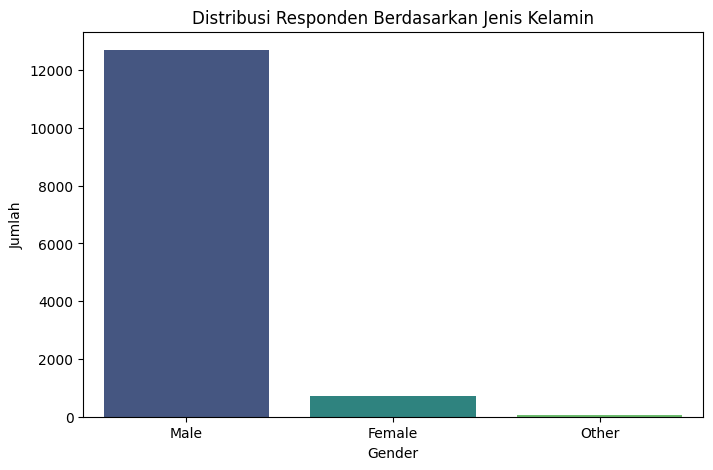

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# Mengatur ukuran gambar
plt.figure(figsize=(8, 5))

# Membuat barplot untuk kolom 'Gender'
sns.countplot(data=df, x='Gender', palette='viridis')

# Memberikan judul dan label
plt.title('Distribusi Responden Berdasarkan Jenis Kelamin')
plt.xlabel('Gender')
plt.ylabel('Jumlah')

# Menampilkan diagram
plt.show()

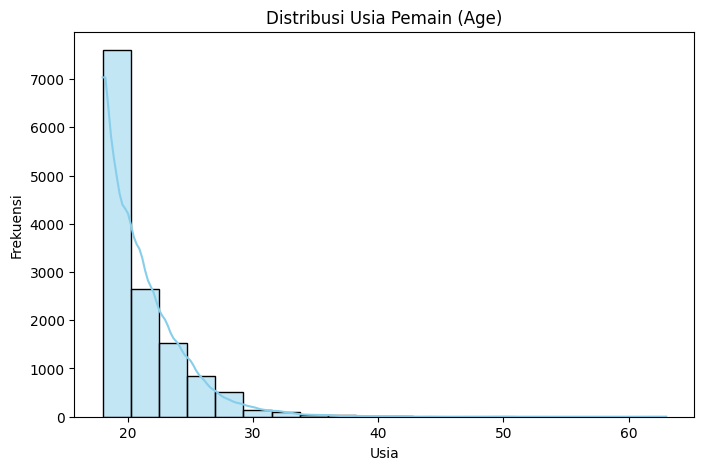

In [10]:
plt.figure(figsize=(8, 5))

# Membuat histogram dengan kurva KDE (kernel density estimate)
sns.histplot(df['Age'].dropna(), bins=20, kde=True, color='skyblue')

plt.title('Distribusi Usia Pemain (Age)')
plt.xlabel('Usia')
plt.ylabel('Frekuensi')

plt.show()

C:\Users\Zakie\AppData\Local\Temp\ipykernel_39876\3607076183.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_filtered, x='Gender', y='Hours', palette='Set2')


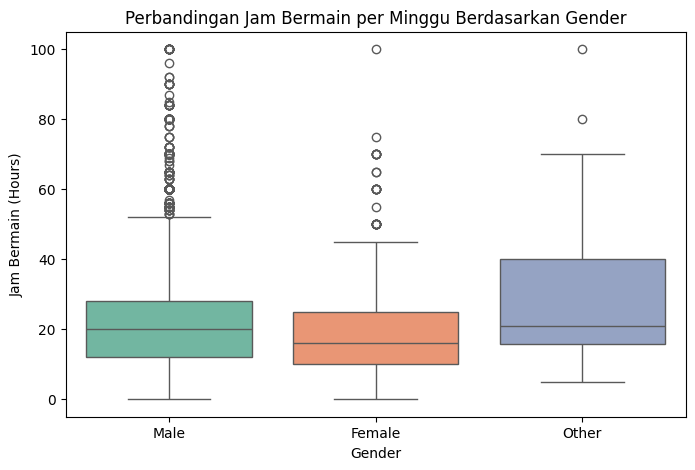

In [11]:
plt.figure(figsize=(8, 5))

# Membuat boxplot antara Gender dan Hours (dibatasi jam bermain di bawah 100 jam agar grafik rapi)
df_filtered = df[df['Hours'] <= 100]
sns.boxplot(data=df_filtered, x='Gender', y='Hours', palette='Set2')

plt.title('Perbandingan Jam Bermain per Minggu Berdasarkan Gender')
plt.xlabel('Gender')
plt.ylabel('Jam Bermain (Hours)')

plt.show()

C:\Users\Zakie\AppData\Local\Temp\ipykernel_39876\1951050887.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=labels, y=counts.values, palette=['#3B528B', '#21918C'])


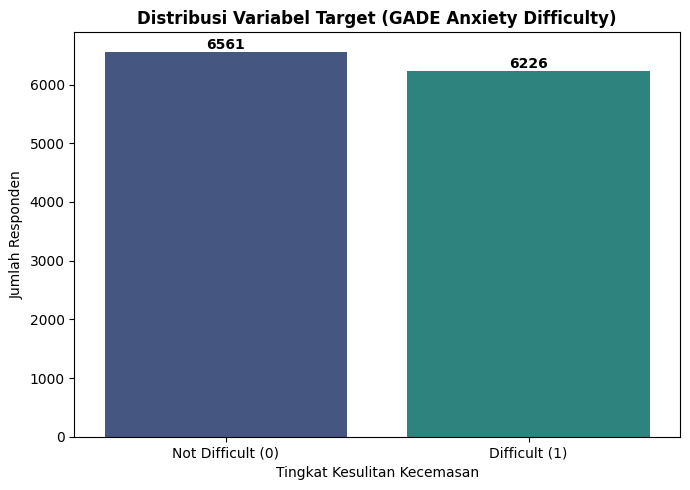

In [12]:

# VISUALISASI 1: GRAFIK DISTRIBUSI TARGET
plt.figure(figsize=(7, 5))
counts = df_model['Target_Binary'].value_counts()
labels = ['Not Difficult (0)', 'Difficult (1)']

ax = sns.barplot(x=labels, y=counts.values, palette=['#3B528B', '#21918C'])
plt.title('Distribusi Variabel Target (GADE Anxiety Difficulty)', fontsize=12, fontweight='bold')
plt.xlabel('Tingkat Kesulitan Kecemasan', fontsize=10)
plt.ylabel('Jumlah Responden', fontsize=10)

# Menambahkan angka frekuensi di atas batang
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='center', xytext=(0, 5), textcoords='offset points', fontweight='bold')

plt.tight_layout()
plt.show()


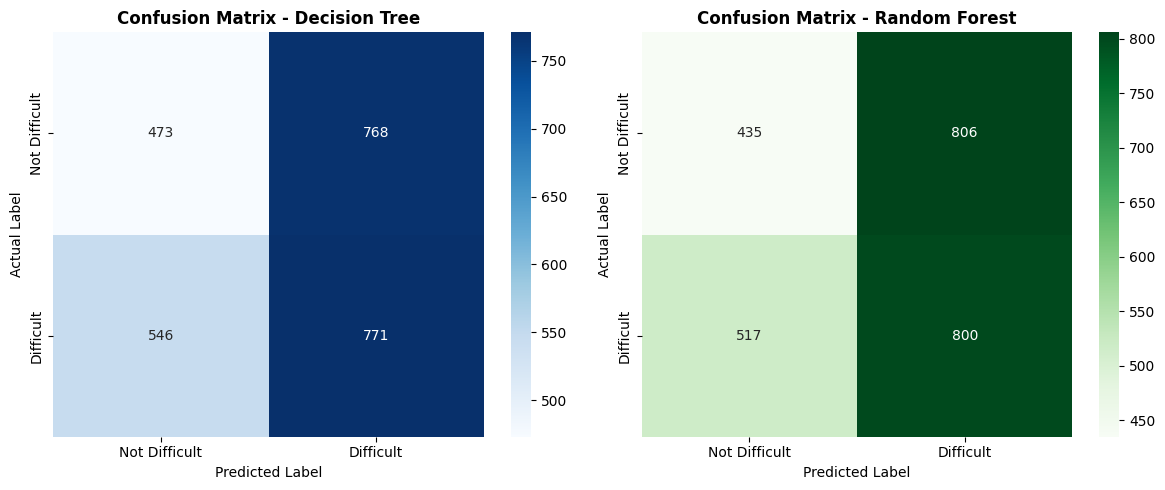

In [13]:
# VISUALISASI 2: MATRIKS KONFUSI / CONFUSION MATRIX
# ==========================================
from sklearn.metrics import confusion_matrix, classification_report
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Confusion Matrix - Decision Tree
cm_dt = confusion_matrix(y_test, y_pred_dt)
sns.heatmap(cm_dt, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Not Difficult', 'Difficult'],
            yticklabels=['Not Difficult', 'Difficult'])
axes[0].set_title('Confusion Matrix - Decision Tree', fontweight='bold')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('Actual Label')

# Confusion Matrix - Random Forest
cm_rf = confusion_matrix(y_test, y_pred_rf)
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Greens', ax=axes[1],
            xticklabels=['Not Difficult', 'Difficult'],
            yticklabels=['Not Difficult', 'Difficult'])
axes[1].set_title('Confusion Matrix - Random Forest', fontweight='bold')
axes[1].set_xlabel('Predicted Label')
axes[1].set_ylabel('Actual Label')

plt.tight_layout()
plt.show()

C:\Users\Zakie\AppData\Local\Temp\ipykernel_39876\2457197807.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax_imp = sns.barplot(data=df_importance, x='Kepentingan', y='Fitur', palette='mako')


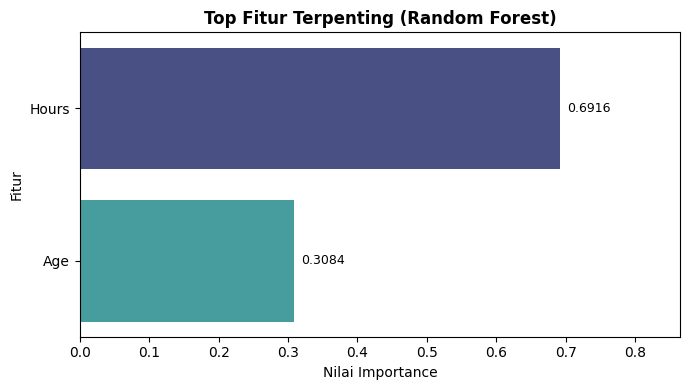

In [14]:
# VISUALISASI 3: FEATURE IMPORTANCE
# ==========================================
df_importance = pd.DataFrame({
    'Fitur': X.columns,
    'Kepentingan': rf_model.feature_importances_
}).sort_values(by='Kepentingan', ascending=False)

plt.figure(figsize=(7, 4))
ax_imp = sns.barplot(data=df_importance, x='Kepentingan', y='Fitur', palette='mako')
plt.title('Top Fitur Terpenting (Random Forest)', fontsize=12, fontweight='bold')
plt.xlabel('Nilai Importance', fontsize=10)
plt.ylabel('Fitur', fontsize=10)

# Menambahkan angka nilai importance di ujung batang
for p in ax_imp.patches:
    width = p.get_width()
    ax_imp.annotate(f'{width:.4f}', 
                    (width + 0.01, p.get_y() + p.get_height() / 2.), 
                    ha='left', va='center', fontsize=9)

plt.xlim(0, max(df_importance['Kepentingan']) * 1.25)
plt.tight_layout()
plt.show()

## analisis Skor MAE, MSE, dan R²
Studi literatur ilmiah yang komprehensif mengenai metrik evaluasi model dapat ditemukan dalam jurnal yang ditulis oleh Chicco, Warrens, dan Jurman (2021) dalam PeerJ Computer Science berjudul "The coefficient of determination R-squared is more informative than SMAPE, MAE, MAPE, MSE and RMSE in regression analysis evaluation". Penelitian tersebut membahas secara mendalam karakteristik matematis, keunggulan, serta keterbatasan dari berbagai metrik evaluasi seperti MAE, MSE, dan $R^2$, termasuk bagaimana MSE memberikan penalti lebih besar pada galat (error) yang tinggi akibat proses pengkuadratan serta bagaimana R^2 merepresentasikan proporsi varians data.

Berdasarkan hasil evaluasi pada gambar, skor tersebut dinilai sangat buruk karena penggunaan metrik regresi pada model klasifikasi menghasilkan nilai eror yang tinggi dan nilai $R^2$ yang bernilai negatif. Nilai Mean Absolute Error (MAE) dan Mean Squared Error (MSE) yang berada di kisaran 0,51 menunjukkan bahwa rata-rata kesalahan prediksi model cukup besar. Dalam konteks klasifikasi biner (kategori 0 dan 1), nilai eror sekitar 0,5 menyiratkan bahwa model sering kali salah menebak kelas secara konsisten, hampir mendekati tebakan acak.

Selain itu, nilai R^2 (R-squared) yang bernilai negatif (sekitar -1,05 hingga -1,07) memberikan indikasi yang lebih kuat mengenai buruknya performa model. Secara statistik, nilai $R^2$ negatif berarti model prediksi yang dibuat justru bekerja jauh lebih buruk daripada sekadar menggunakan nilai rata-rata data target sebagai acuan konstan. Hal ini terjadi karena metrik-metrik tersebut dipaksakan untuk mengukur data diskrit (klasifikasi) menggunakan formula yang dirancang khusus untuk variabel kontinu (regresi), sehingga interpretasi kecocokan garis atau pola datanya menjadi sangat tidak akurat.




In [15]:
# 1. Mengimpor fungsi metrik regresi dari scikit-learn
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 2. Menghitung metrik untuk Decision Tree (menggunakan y_test dan y_pred_dt)
mae_dt = mean_absolute_error(y_test, y_pred_dt)
mse_dt = mean_squared_error(y_test, y_pred_dt)
r2_dt = r2_score(y_test, y_pred_dt)

print("="*40)
print("EVALUASI METRIK REGRESI - DECISION TREE")
print("="*40)
print(f"MAE : {mae_dt:.4f}")
print(f"MSE : {mse_dt:.4f}")
print(f"R2  : {r2_dt:.4f}")

# 3. Menghitung metrik untuk Random Forest (menggunakan y_test dan y_pred_rf)
mae_rf = mean_absolute_error(y_test, y_pred_rf)
mse_rf = mean_squared_error(y_test, y_pred_rf)
r2_rf = r2_score(y_test, y_pred_rf)

print("\n" + "="*40)
print("EVALUASI METRIK REGRESI - RANDOM FOREST")
print("="*40)
print(f"MAE : {mae_rf:.4f}")
print(f"MSE : {mse_rf:.4f}")
print(f"R2  : {r2_rf:.4f}")

EVALUASI METRIK REGRESI - DECISION TREE
MAE : 0.5137
MSE : 0.5137
R2  : -1.0565

EVALUASI METRIK REGRESI - RANDOM FOREST
MAE : 0.5172
MSE : 0.5172
R2  : -1.0706
